<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-0/07-graficos/solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Solución 0.7 · Gráficos

**Serie:** Del Excel al Machine Learning · **Temporada 0** · 🎬 Video próximamente

Estas son las respuestas del ejercicio. Si tu gráfico se ve distinto pero dice lo mismo, ¡también está bien! Títulos y colores son decisión tuya.

### Prepara los datos

Ejecuta estas dos celdas. Abren las ventas y les agregan el año, el mes y la categoría del producto.

En cada gráfico, escribe un título y los nombres de los ejes, con sus **unidades**, y termina con `plt.show()`. Muestra los montos en miles de soles.

Haz cada gráfico en su celda, y **ejecuta los ejercicios en orden**: algunos usan variables de los anteriores.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
ventas = pd.read_csv(DATOS + "ventas.csv")
productos = pd.read_csv(DATOS + "productos.csv")

ventas["fecha"] = pd.to_datetime(ventas["fecha"], format="%Y-%m-%d")
ventas["anio"] = ventas["fecha"].dt.year
ventas["mes"] = ventas["fecha"].dt.month

ventas = pd.merge(ventas, productos[["id_producto", "categoria"]], on="id_producto", how="left")

ventas.shape

(50000, 14)

### 1. Las categorías

Haz un gráfico de barras horizontales (`kind="barh"`) con las ventas por `categoria`, ordenadas de mayor a menor. Se leen los nombres sin girar la cabeza. Pero ¿qué pasa con el orden? Ajusta tu `.sort_values()` para que Abarrotes quede **arriba**. Su barra debe llegar cerca de 3,884.

> 💡 Con barras horizontales, los soles van en el eje horizontal (`xlabel`) y las categorías en el vertical (`ylabel`).

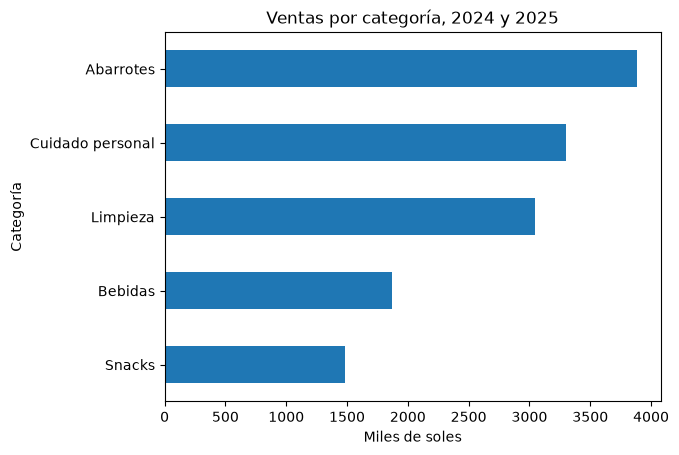

In [3]:
por_categoria = ventas.groupby("categoria")["total"].sum().sort_values() / 1000

por_categoria.plot(
    kind="barh",
    title="Ventas por categoría, 2024 y 2025",
    xlabel="Miles de soles",
    ylabel="Categoría",
)
plt.show()

Las barras horizontales se dibujan de abajo hacia arriba. Por eso ordenamos de menor a mayor: así Abarrotes queda arriba.

### 2. El año 2025

Filtra las ventas de 2025 y haz un gráfico de líneas con sus ventas por mes, con un punto en cada mes, los 12 meses en el eje y el eje vertical desde 0.

Diciembre debe dar cerca de 795. Enero y febrero se ven muy parecidos: en otra celda, muestra el resumen con `.sort_values()` y escribe en un comentario cuál fue el mes más alto y cuál el más bajo.

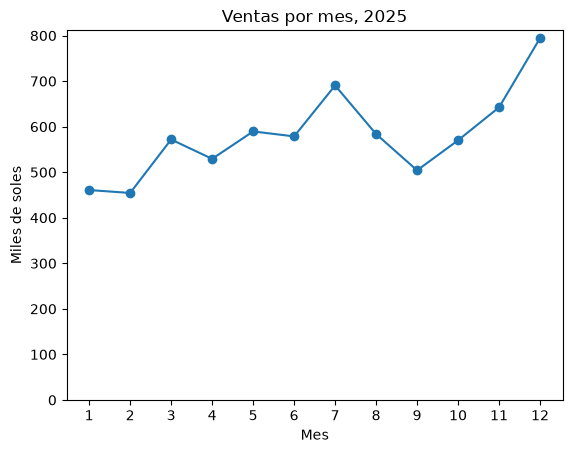

In [4]:
ventas_2025 = ventas[ventas["anio"] == 2025]
por_mes = ventas_2025.groupby("mes")["total"].sum() / 1000

por_mes.plot(
    kind="line",
    marker="o",
    title="Ventas por mes, 2025",
    xlabel="Mes",
    ylabel="Miles de soles",
    xticks=range(1, 13),
    ylim=(0, None),
)
plt.show()

In [5]:
por_mes.sort_values()

# El mes más alto fue diciembre, y el más bajo, febrero.

mes
2     454.48115
1     460.85077
9     504.08531
4     529.33129
10    570.12409
3     571.89543
6     578.67202
8     583.77586
5     589.54273
11    642.48404
7     690.48509
12    794.51497
Name: total, dtype: float64

### 3. Ciudades, año contra año

Con `pivot_table`, arma una tabla con `ciudad` en las filas y `anio` en las columnas. Haz con ella un gráfico de columnas: cada ciudad debe tener **dos columnas**. Cambia el título de la leyenda a `Año`. Lima 2025 debe llegar cerca de 2,616.

El gráfico no alcanza para saber qué ciudad creció más en soles. En otra celda, resta las dos columnas y ordena. Si tu tabla se llama `ciudad_anio`, es `ciudad_anio[2025] - ciudad_anio[2024]`: el año va sin comillas porque es un número.

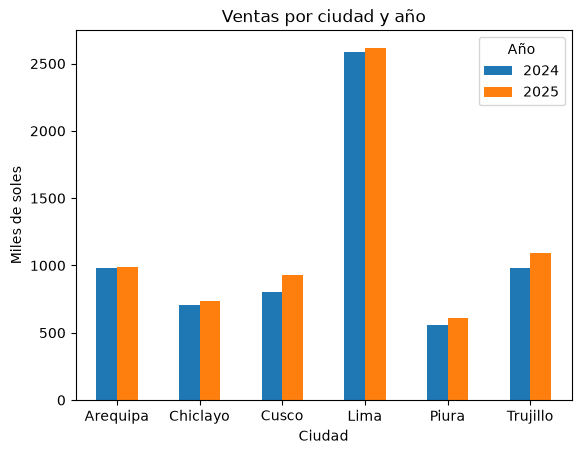

In [6]:
ciudad_anio = (
    ventas.pivot_table(index="ciudad", columns="anio", values="total", aggfunc="sum") / 1000
)

ciudad_anio.plot(
    kind="bar",
    title="Ventas por ciudad y año",
    xlabel="Ciudad",
    ylabel="Miles de soles",
    rot=0,
)
plt.legend(title="Año")
plt.show()

In [7]:
(ciudad_anio[2025] - ciudad_anio[2024]).sort_values(ascending=False)

ciudad
Cusco       128.12549
Trujillo    110.83284
Piura        52.71850
Chiclayo     30.35109
Lima         27.17031
Arequipa      9.00066
dtype: float64

Cusco creció más, unos S/ 128 mil, y le sigue Trujillo, con unos S/ 111 mil. Arequipa fue la que menos creció, unos S/ 9 mil. Lima, aunque es la más grande, solo creció unos S/ 27 mil.

### 4. Las partes del total

Haz un gráfico circular con la parte de cada `categoria` en las ventas totales, con los porcentajes visibles. Los porcentajes deben sumar cerca de 100.

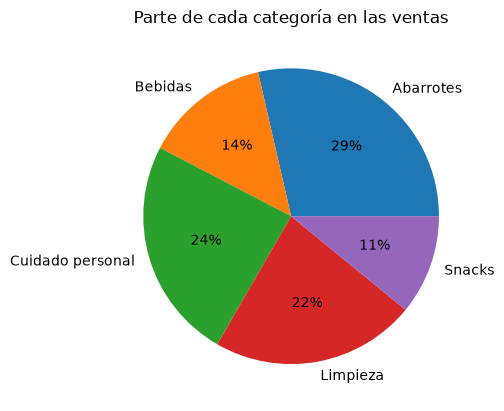

In [8]:
ventas.groupby("categoria")["total"].sum().plot(
    kind="pie",
    autopct="%1.0f%%",
    title="Parte de cada categoría en las ventas",
    ylabel="",
)
plt.show()

### 5. ¿Se toma más en verano?

Filtra las ventas de `Bebidas` y haz un gráfico de líneas con una línea por año, de enero a diciembre. Diciembre de 2025 debe dar cerca de 100. ¿En qué meses se venden más? ¿Coincide con el verano peruano, de diciembre a marzo?

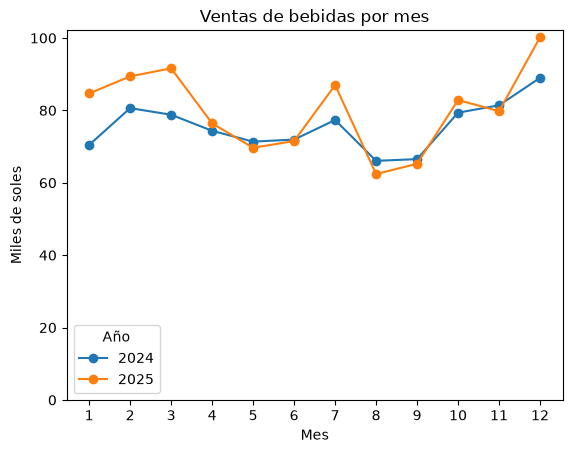

In [9]:
bebidas = ventas[ventas["categoria"] == "Bebidas"]
bebidas_mes = bebidas.pivot_table(index="mes", columns="anio", values="total", aggfunc="sum") / 1000

bebidas_mes.plot(
    kind="line",
    marker="o",
    title="Ventas de bebidas por mes",
    xlabel="Mes",
    ylabel="Miles de soles",
    xticks=range(1, 13),
    ylim=(0, None),
)
plt.legend(title="Año")
plt.show()

Coincide en parte. Febrero y marzo destacan en los dos años, y enero solo en 2025. Diciembre es el pico, pero ahí sube toda la empresa por Navidad; julio también sube, por Fiestas Patrias. Y octubre y noviembre son altos sin ser verano. Los datos reales rara vez cuentan una historia perfecta. Lo útil es comparar: en enero y febrero, las ventas totales están en su punto más bajo, pero las de bebidas no caen tanto.

### 6. Un tipo nuevo: el histograma

¿Cómo se reparten los montos de las ventas? Un **histograma** agrupa los valores en rangos y cuenta cuántos caen en cada uno. En Excel existe desde la versión 2016, entre los gráficos de **Insertar**.

Hazlo con la columna `total`, con `kind="hist"` y `bins=50`, que indica cuántos rangos dibujar. Esta vez los montos van en soles. ¿Se parece a lo que viste en el 0.6 con el promedio y la mediana? ¿Por qué?

> 💡 Aquí el eje vertical cuenta ventas, así que `ylabel="Número de ventas"`.

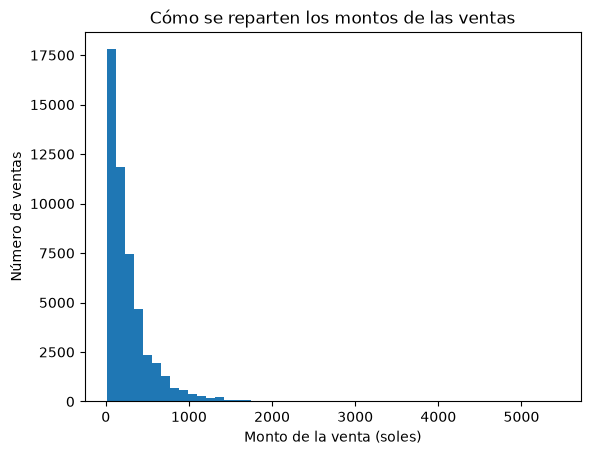

In [10]:
ventas["total"].plot(
    kind="hist",
    bins=50,
    title="Cómo se reparten los montos de las ventas",
    xlabel="Monto de la venta (soles)",
    ylabel="Número de ventas",
)
plt.show()

Sí: hay muchísimas ventas pequeñas y una "cola" larga de pocas ventas grandes. Esa cola jala el promedio (S/ 272) por encima de la mediana (S/ 180).

### 7. El gráfico para la gerencia

Elige el gráfico que más te haya sorprendido. Cambia su título para que **diga la conclusión**, no el tema. Por ejemplo, no "Ventas por mes", sino "Julio y diciembre son nuestros mejores meses".

Guárdalo como `para_gerencia.png`, búscalo en la carpeta 📁 y ábrelo. Si está en blanco, pusiste `plt.savefig()` después de `plt.show()`.

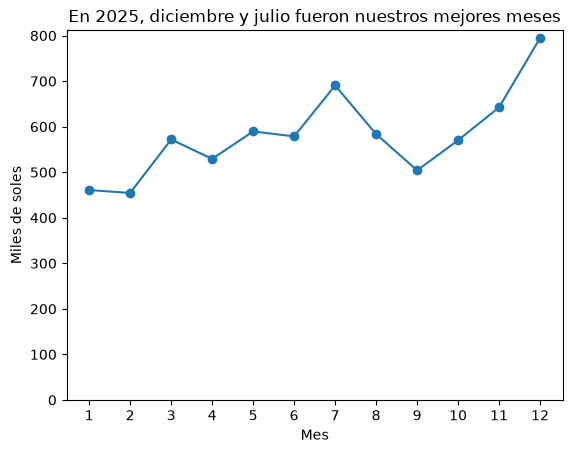

In [11]:
por_mes.plot(
    kind="line",
    marker="o",
    title="En 2025, diciembre y julio fueron nuestros mejores meses",
    xlabel="Mes",
    ylabel="Miles de soles",
    xticks=range(1, 13),
    ylim=(0, None),
)
plt.savefig("para_gerencia.png", dpi=150, bbox_inches="tight")
plt.show()

## 🎉 ¡Bien hecho!

Nos vemos en el **episodio 0.8: Miniproyecto, automatiza tu reporte mensual**.

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0